In [15]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [6]:


def black_scholes_call(S, K, T, r, sigma, q=0):
    """
    Price a European option using the Black–Scholes model.

    Parameters:
        S      : Current price of the underlying asset.
        K      : Option strike (exercise) price.
        T      : Time to expiration, in years.
        r      : Annualized risk-free interest rate, as a decimal.
        sigma  : Annualized volatility of the underlying, as a decimal.
        q      : Annualized continuous dividend yield, as a decimal; defaults to 0.
        
    """


    if S <= 0 or K <= 0:
        raise ValueError("S and K must be positive")

    if T <= 0 or sigma <= 0:
        raise ValueError("T and sigma must be positive")

    

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    
    return (
            S * np.exp(-q*T) * norm.cdf(d1)
            - K * np.exp(-r*T) * norm.cdf(d2)
        )

def black_scholes_put(S, K, T, r, sigma, q=0):
    """
        Price a European option using the Black–Scholes model.
    
        Parameters:
            S      : Current price of the underlying asset.
            K      : Option strike (exercise) price.
            T      : Time to expiration, in years.
            r      : Annualized risk-free interest rate, as a decimal.
            sigma  : Annualized volatility of the underlying, as a decimal.
            q      : Annualized continuous dividend yield, as a decimal; defaults to 0.
            
        """

    if( S <= 0 or K <= 0):
        raise ValueError("S and K must be positive")

    if T <= 0 or sigma <= 0:
        raise ValueError("T and sigma must be positive")

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    
    return (
            K * np.exp(-r*T) * norm.cdf(-d2)
            - S * np.exp(-q*T) * norm.cdf(-d1)
        )



In [ ]:
S = 1
K = 5
T = 1
r = 0.05
sigma = 0.20

call = black_scholes_call(S, K, T, r, sigma)
put = black_scholes_put(S, K, T, r, sigma)

print("Call Price:", call)
print("Put Price:", put)

lhs = call - put
rhs = S - K * np.exp(-r*T)

print("Put-call parity error:", abs(lhs-rhs))

Call Price: 5.367287066219319e-30
Put Price: 85.1229424500714
Put-call parity error: 0.0


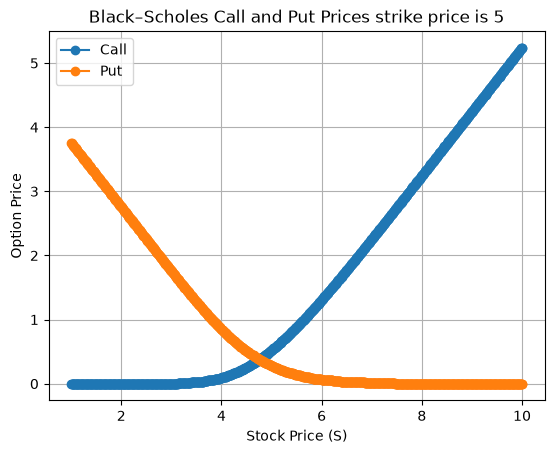

In [17]:
K = 5
T = 1
r = 0.05
sigma = 0.20
stock_value = np.linspace(1, 10, 1000)
call_val=[round(black_scholes_call(S, K, T, r, sigma),2) for S in stock_value]
put_val=[round(black_scholes_put(S, K, T, r, sigma),2) for S in stock_value]


plt.plot(stock_value, call_val, marker="o", label="Call")
plt.plot(stock_value, put_val, marker="o", label="Put")

plt.xlabel("Stock Price (S)")
plt.ylabel("Option Price")
plt.title("Black–Scholes Call and Put Prices strike price is 5")
plt.legend()
plt.grid(True)
plt.show()
    
    
    



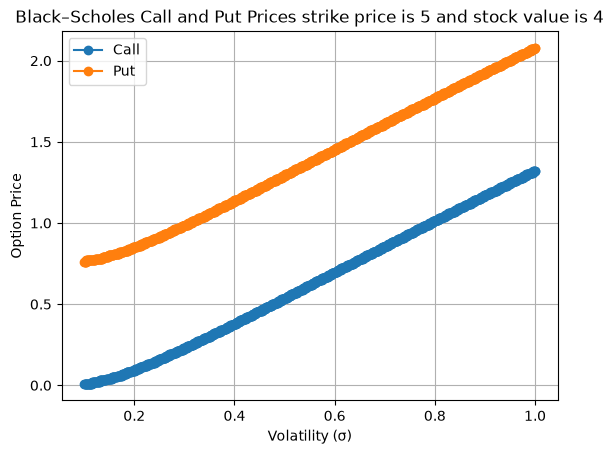

In [19]:
K = 5
T = 1
r = 0.05
sigma = np.linspace(0.1,1,1000)
stock_value=4
call_val=[round(black_scholes_call(stock_value, K, T, r, s),2) for s in sigma]
put_val=[round(black_scholes_put(stock_value, K, T, r, s),2) for s in sigma]

plt.plot(sigma, call_val, marker="o", label="Call")
plt.plot(sigma, put_val, marker="o", label="Put")

plt.xlabel("Volatility (σ)")
plt.ylabel("Option Price")
plt.title("Black–Scholes Call and Put Prices strike price is 5 and stock value is 4")
plt.legend()
plt.grid(True)
plt.show()